In [ ]:
!pip install -q ultralytics split-folders kagglehub matplotlib

In [ ]:
import kagglehub

dataset_raw_path = kagglehub.dataset_download("danielrey96/colombian-sign-language-lsc-alphabet")
print("Dataset descargado en:", dataset_raw_path)

Using Colab cache for faster access to the 'colombian-sign-language-lsc-alphabet' dataset.
Dataset descargado en: /kaggle/input/colombian-sign-language-lsc-alphabet


In [ ]:
import os, shutil

# 1. Encontrar la carpeta real del dataset (está en solo lectura)
real_data_dir = dataset_raw_path
for root, dirs, files in os.walk(dataset_raw_path):
    if len(dirs) >= 10:
        real_data_dir = root
        break

# 2. Copiarla a una carpeta editable
data_dir = "/content/dataset_unificado"
if os.path.exists(data_dir):
    shutil.rmtree(data_dir)
shutil.copytree(real_data_dir, data_dir)
print("Carpetas del dataset original:", sorted(os.listdir(data_dir)))

# 3. Descomprimir tus fotos (limpia una versión anterior si existe)
!rm -rf mis_datos
!unzip -q -o mis_datos.zip -d .
print("Carpetas en mis_datos:", sorted(os.listdir("mis_datos")))

# 4. Copiar tus fotos dentro de cada letra
for letra in sorted(os.listdir("mis_datos")):
    destino = os.path.join(data_dir, letra)
    if not os.path.isdir(destino):
        print(f"⚠️ La carpeta '{letra}' no existe en el dataset original, revisa el nombre")
        continue
    fotos = os.listdir(f"mis_datos/{letra}")
    for f in fotos:
        shutil.copy(f"mis_datos/{letra}/{f}", os.path.join(destino, f"mio_{f}"))
    print(f"{letra}: +{len(fotos)} fotos tuyas -> {len(os.listdir(destino))} en total")

Carpetas del dataset original: ['A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'T', 'U', 'V', 'W', 'X', 'Y']
Carpetas en mis_datos: ['A', 'B', 'C', 'D', 'E', 'F', 'H', 'I', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'T', 'U', 'V', 'W', 'X', 'Y']
A: +130 fotos tuyas -> 381 en total
B: +124 fotos tuyas -> 374 en total
C: +101 fotos tuyas -> 376 en total
D: +91 fotos tuyas -> 350 en total
E: +121 fotos tuyas -> 308 en total
F: +101 fotos tuyas -> 333 en total
H: +126 fotos tuyas -> 300 en total
I: +116 fotos tuyas -> 376 en total
K: +107 fotos tuyas -> 359 en total
L: +102 fotos tuyas -> 352 en total
M: +88 fotos tuyas -> 343 en total
N: +91 fotos tuyas -> 341 en total
O: +114 fotos tuyas -> 367 en total
P: +143 fotos tuyas -> 392 en total
Q: +122 fotos tuyas -> 372 en total
R: +114 fotos tuyas -> 396 en total
T: +92 fotos tuyas -> 342 en total
U: +97 fotos tuyas -> 349 en total
V: +92 fotos tuyas -> 342 en total
W: +112 fotos tuyas -> 368 en total
X: +101 fo

In [ ]:
import os, shutil, splitfolders

if os.path.exists("./dataset_lsc_yolo"):
    shutil.rmtree("./dataset_lsc_yolo")

splitfolders.ratio(
    data_dir,
    output="./dataset_lsc_yolo",
    seed=42,
    ratio=(0.8, 0.2),
    group_prefix=None
)

train_classes = os.listdir("./dataset_lsc_yolo/train")
print(f"✅ Se encontraron {len(train_classes)} carpetas de letras en train:")
print(sorted(train_classes))

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11s-cls.pt")

results = model.train(
    data="./dataset_lsc_yolo",
    epochs=30,
    imgsz=256,
    batch=32,
    name="lsc_v2",
    hsv_h=0.03, hsv_s=0.6, hsv_v=0.5,
    degrees=15, translate=0.15, scale=0.4, erasing=0.4,
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./dataset_lsc_yolo, degrees=15, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, 

📁 Mostrando resultados desde: /content/runs/classify/lsc_v2

📊 Archivo: confusion_matrix.png


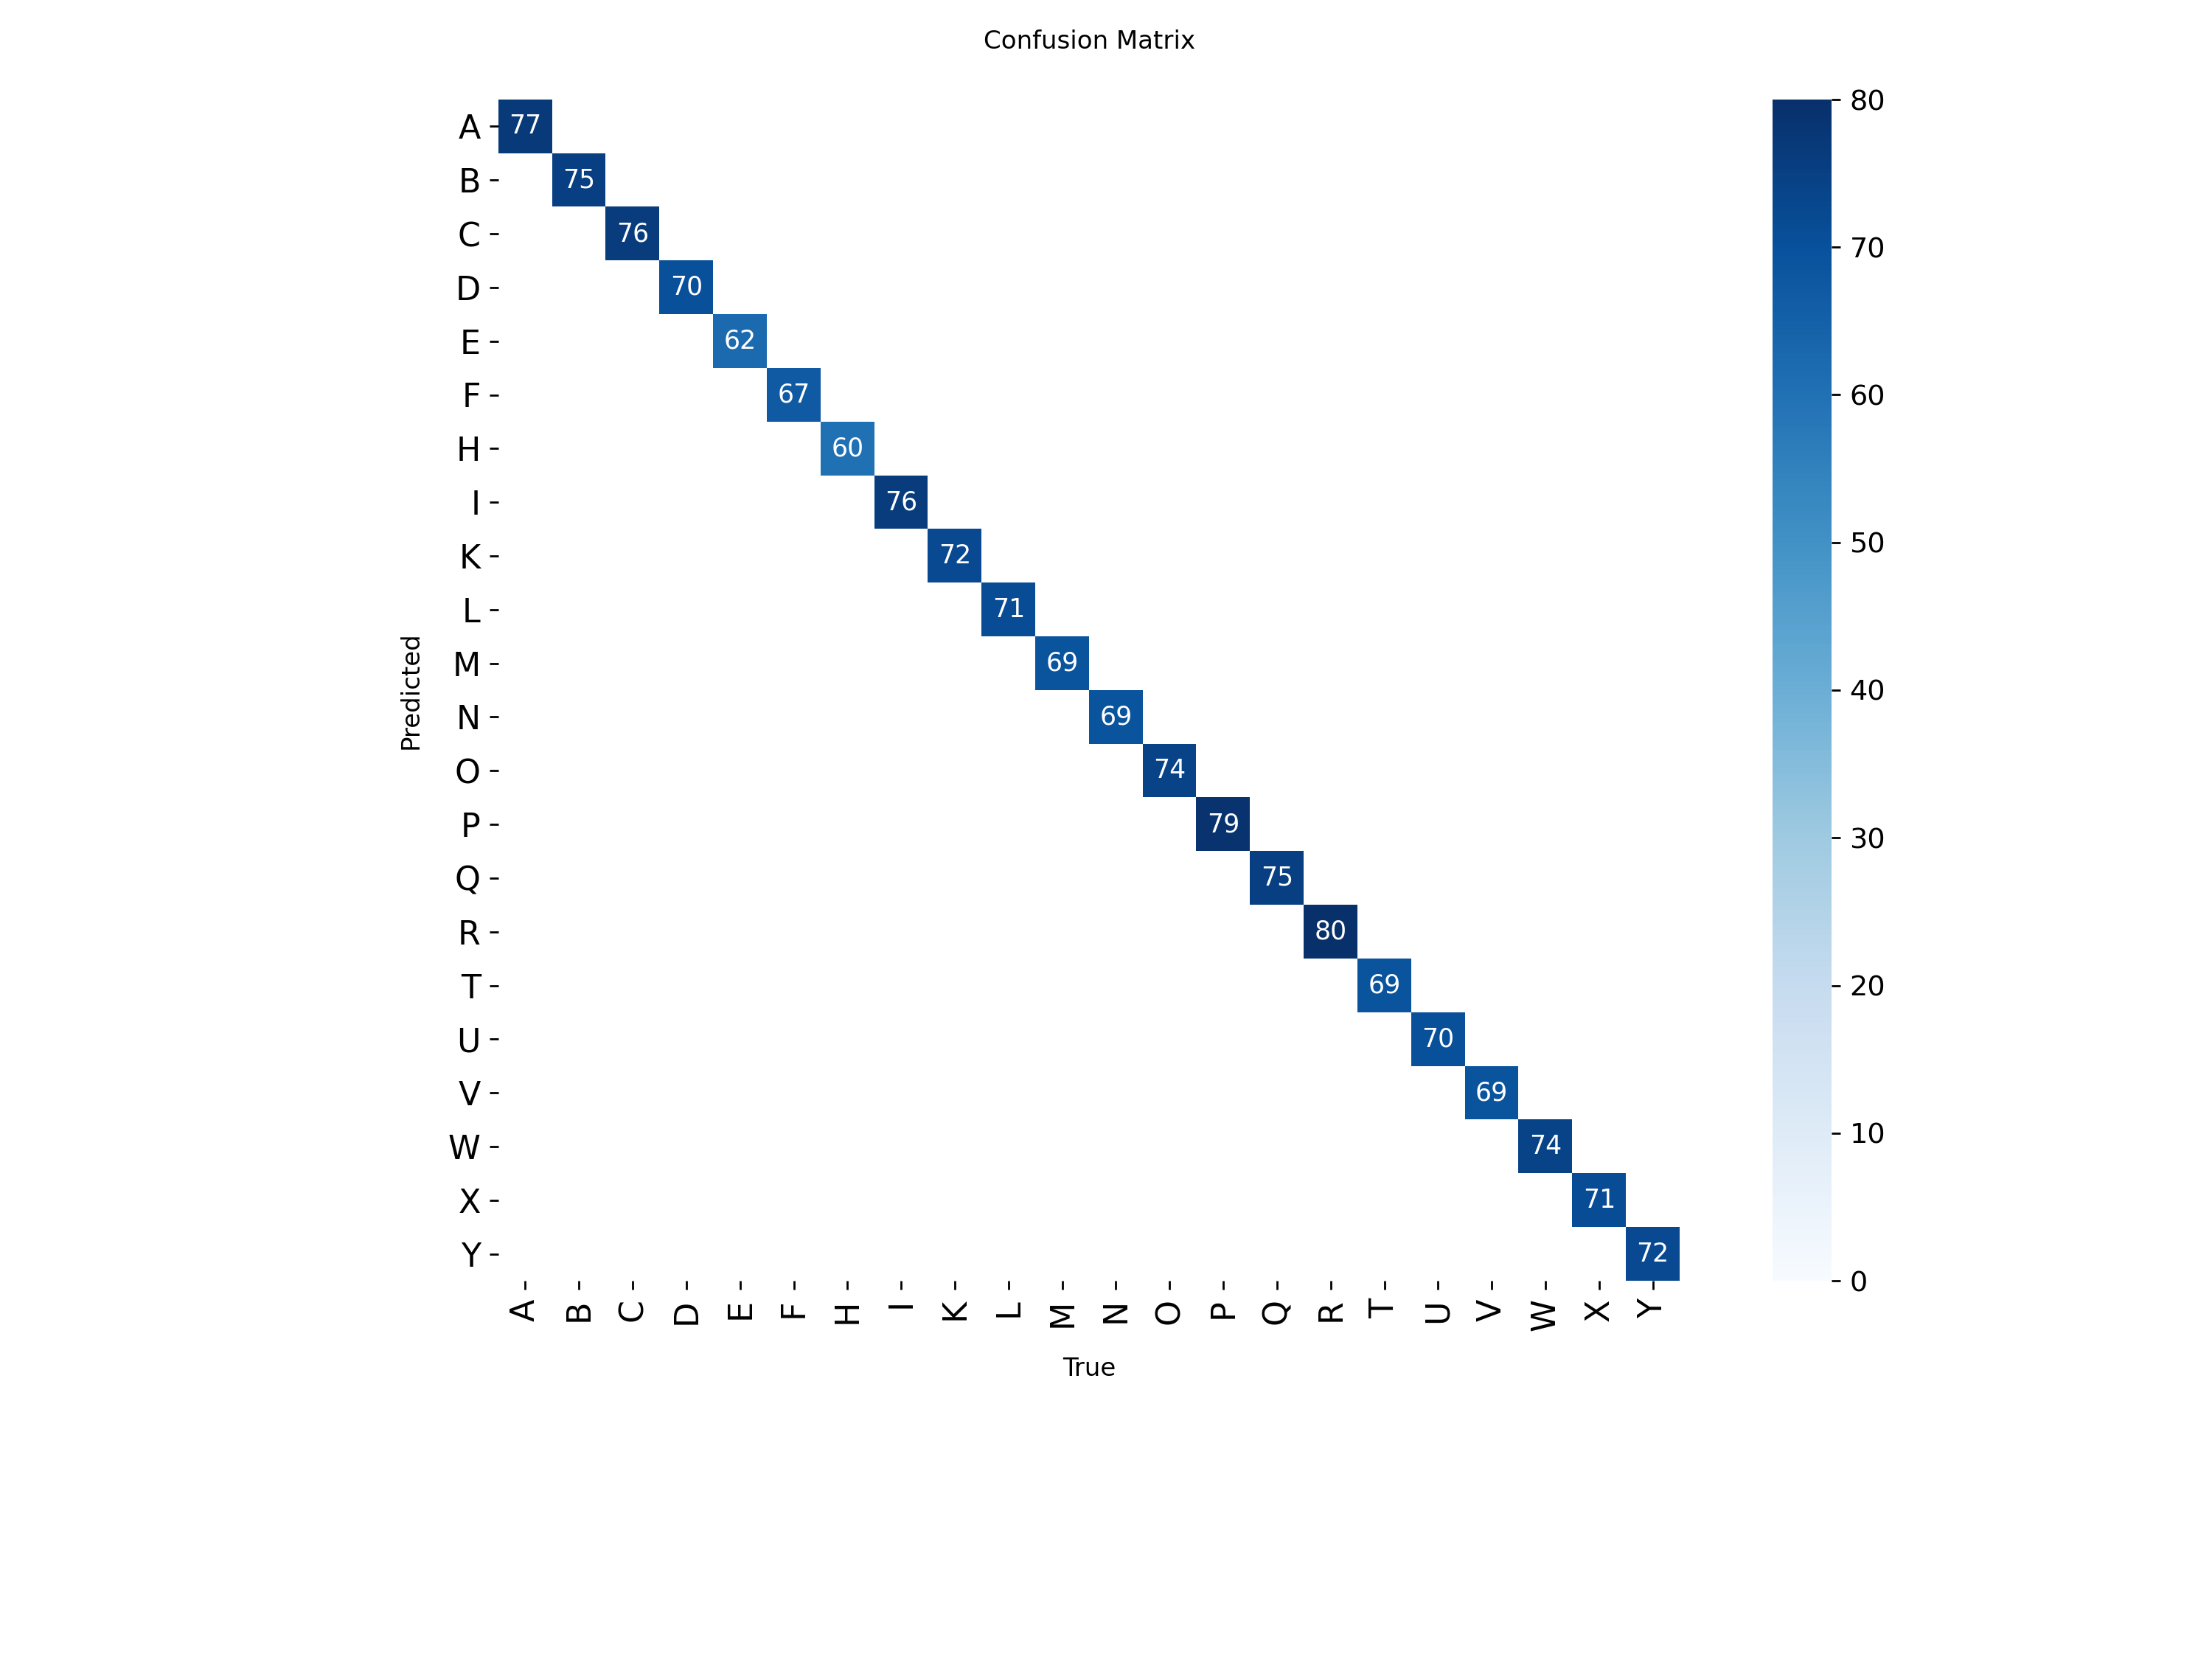

📊 Archivo: confusion_matrix_normalized.png


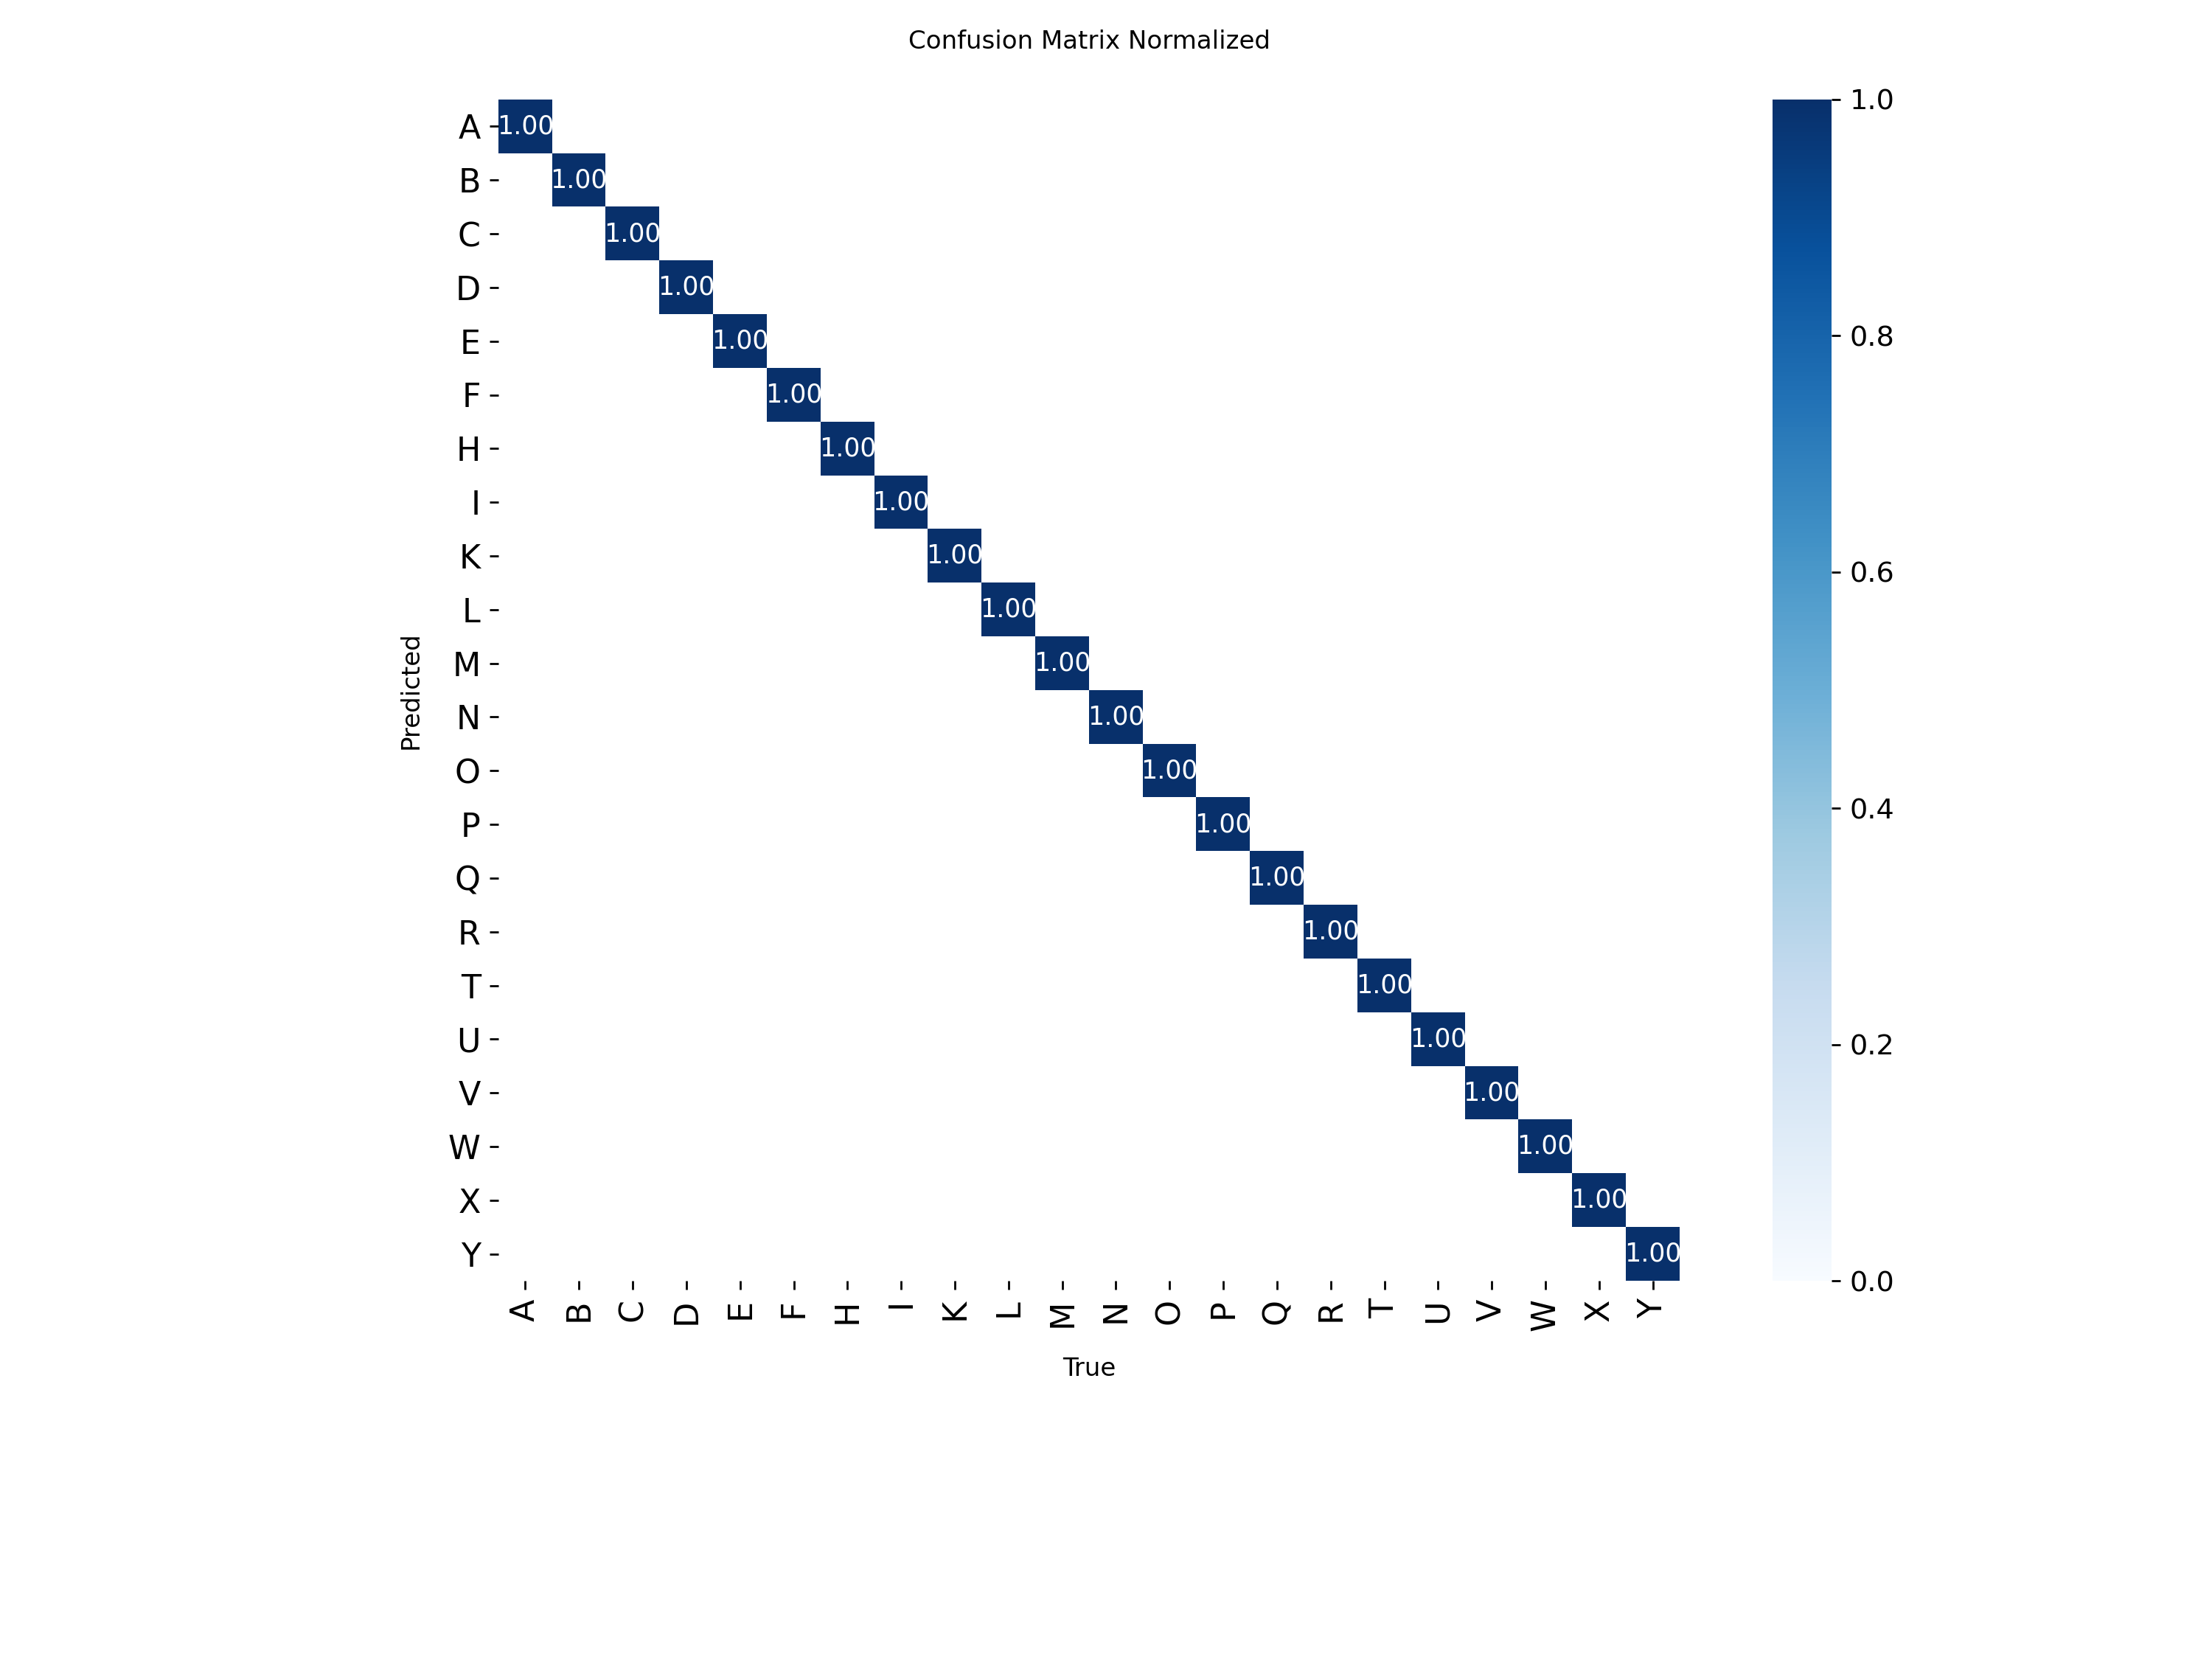

📊 Archivo: results.png


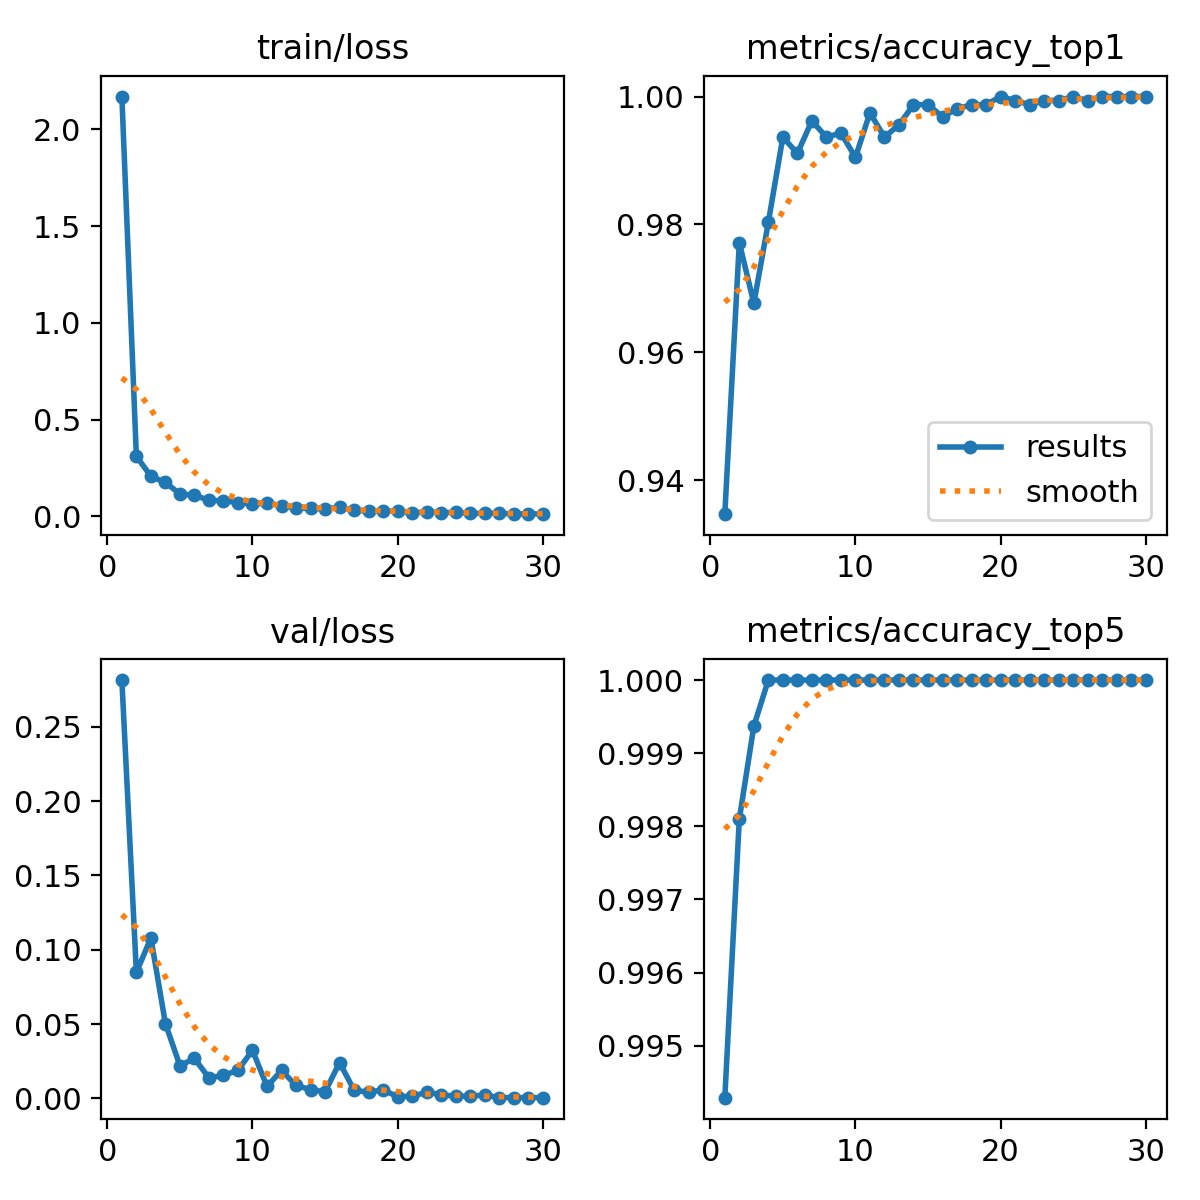

In [ ]:
import os
import glob
from IPython.display import Image, display

save_dir = str(model.trainer.save_dir)
print(f"📁 Mostrando resultados desde: {save_dir}\n")

png_files = glob.glob(os.path.join(save_dir, "*.png"))

if png_files:
    for filepath in sorted(png_files):
        filename = os.path.basename(filepath)
        if any(keyword in filename for keyword in ["confusion", "results", "val_batch"]):
            print(f"📊 Archivo: {filename}")
            display(Image(filename=filepath))
else:
    print("⚠️ No se encontraron gráficas en la carpeta de salida.")

In [ ]:
import os
import glob
from google.colab import files

best_weights_path = ""

if hasattr(model, 'trainer') and model.trainer is not None:
    best_weights_path = os.path.join(str(model.trainer.save_dir), "weights", "best.pt")

if not os.path.exists(best_weights_path):
    pt_files = glob.glob("runs/classify/*/weights/best.pt")
    if pt_files:
        best_weights_path = max(pt_files, key=os.path.getmtime)

if os.path.exists(best_weights_path):
    print(f"✅ ¡Archivo encontrado! Descargando desde: {best_weights_path}")
    files.download(best_weights_path)
else:
    print("⚠️ No se encontró ningún archivo best.pt. Ejecuta primero la celda de entrenamiento.")

✅ ¡Archivo encontrado! Descargando desde: /content/runs/classify/lsc_v2/weights/best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>